# Gradient dominance experiments

Empirical check of Theorem 4.3 (gradient dominance) from Gatmiry et al. (2024) for **looped** linear transformers.

Assumptions from the paper that are enforced here:
- Population covariance $\Sigma^* = I$ (the `normal` data mode, `U = D = None`).
<!-- [P-FIX] Corrected description of the P parameterization (Section 3.5 of the paper). -->
- Paper parameterization (Section 3.5): $Q = \begin{bmatrix} A & 0 \\ 0 & 0 \end{bmatrix}$ and $P = \begin{bmatrix} 0_{d \times d} & 0 \\ u^\top & 1 \end{bmatrix}$. The model's learnable $d \times d$ block of $P$ is the top-left block, which the paper always fixes at $0$, so it is zeroed and frozen and only $Q$ (the preconditioner $A$) is trained.
- $u = 0$: this holds automatically, because the model has no $u$ parameter (the last row of $P$ is hard-coded to $[0, \dots, 0, 1]$). The effective $P$ is therefore $\begin{bmatrix} 0 & 0 \\ 0 & 1 \end{bmatrix}$.

Theorem 4.3: if
$$\mathcal{L}(A, 0) \ge \frac{16 d^{3/2} L d 4^L}{\sqrt{n}},$$
then
$$\|\nabla_A \mathcal{L}(A, 0)\|^2 \ge \frac{L - \frac{1}{2}}{4 d^{(L-1)/(2L-1)}} \mathcal{L}(A, 0)^{(2L-1)/L}.$$

Here $n$ is the context length `N` and $L$ is the number of loops.

The last section repeats the experiment with a non-identity population covariance $\Sigma^* = U D^2 U^\top$. Theorem 4.3 assumes $\Sigma^* = I$, so that section goes beyond what the paper proves.

In [1]:
# Imports and setup

import torch
from matplotlib import pyplot as plt
import os
import time
import numpy as np

from experiments_helper import build_transformer, step
from linear_transformer import generate_data, in_context_loss

np.set_printoptions(precision=2, suppress=True)
torch.set_printoptions(precision=2)

log_dir = 'log'
cur_dir = log_dir
os.makedirs(cur_dir, exist_ok=True)

In [2]:
# Problem parameters (defined in experiments_helper.py; edit them there so the
# helper functions see the same values)

from experiments_helper import (
    device, lr, clip_r, normal_data_mode, B, n_head, var,
    max_iters, stride,
)

# Revised parameters
alg = 'sgd'

print(f'Running on device: {device}.')

Running on device: cuda.


## Theorem 4.3 helpers

In [3]:
def get_loss_lower_bound(d, L, n):
    # Loss threshold from Theorem 4.3: (16 d^{3/2} L d 4^L) / sqrt(n).
    return (16 * d ** 1.5 * L * d * 4 ** L) / np.sqrt(n)


def is_loss_lower_bound_valid(loss, loss_lower_bound):
    # True when the loss is large enough for Theorem 4.3 to apply.
    return bool(loss >= loss_lower_bound)


def get_squared_norm(gradients):
    # Left side of Theorem 4.3: ||grad_A L(A, 0)||^2 (squared Frobenius norm).
    return gradients.detach().pow(2).sum().item()


def get_squared_norm_lower_bound(d, L, loss):
    # Right side of Theorem 4.3: (L - 1/2) / (4 d^{(L-1)/(2L-1)}) * loss^{(2L-1)/L}.
    return (L - 0.5) / (4 * d ** ((L - 1) / (2 * L - 1))) * loss ** ((2 * L - 1) / L)


def is_gradient_dominance_valid(squared_norm, squared_norm_lower_bound):
    # True when the gradient dominance inequality holds.
    return bool(squared_norm >= squared_norm_lower_bound)

## Training with gradient dominance tracking

The training loop mirrors `run_experiment_suite(..., freeze_p=True)` in `experiments_helper.py`, but records the loss and the gradient of $Q$ (i.e. $A$) at every iteration, before clipping and before the optimizer step.
<!-- [P-FIX] Corrected: zeroing P's top-left block is the paper's P parameterization, not u = 0. -->
The top-left $d \times d$ block of $P$ is kept at zero to match the paper's parameterization $P = \begin{bmatrix} 0 & 0 \\ u^\top & 1 \end{bmatrix}$; $u = 0$ holds automatically since the model has no $u$ parameter.

In [4]:
def run_gradient_dominance_experiment(seeds, loop_counts, context_lengths=[],
                                      data_mode=normal_data_mode, iters=max_iters,
                                      dim=None, U=None, D=None, covariance_label='identity'):
    # Train looped transformers and evaluate Theorem 4.3 at every iteration.
    # Returns {(seed, L, N): dict of per-iteration numpy arrays}.
    # dim defaults to the global d. U, D give covariates covariance U D^2 U^T
    # (see generate_data); leave them as None for identity covariance.
    if dim is None:
        dim = d
    results = {}
    n_runs = len(seeds) * len(loop_counts) * len(context_lengths)

    # Report the configuration shared by every run before training starts.
    print(f'Gradient dominance experiment: {n_runs} runs')
    print(f'  seeds={list(seeds)}, loop_counts={list(loop_counts)}, '
          f'context_lengths={list(context_lengths)}')
    print(f'  d={dim}, covariance={covariance_label}, data_mode={data_mode}')
    print(f'  alg={alg}, lr={lr}, B={B}, iters={iters}, n_head={n_head}, var={var}, '
          f'clip=None, P frozen (top-left block = 0)')

    run_index = 0
    for seed in seeds:
        for L in loop_counts:
            for context_length in context_lengths:
                key = (seed, L, context_length)
                run_index += 1
                print(f'Run {run_index}/{n_runs}: seed={seed}, L={L}, N={context_length}, '
                      f'd={dim}, covariance={covariance_label}')

                torch.manual_seed(seed)
                model = build_transformer('looped', L, n_head, dim, var).to(device)
                model.zero_p()  # u = 0 assumption: P stays zero for the whole run

                if alg == 'sgd':
                    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=0)
                elif alg == 'adam':
                    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.9), weight_decay=0)
                else:
                    raise ValueError(f'Unsupported optimizer: {alg}')

                loss_lower_bound = get_loss_lower_bound(dim, L, context_length)
                record = {name: np.full(iters, np.nan) for name in (
                    'loss', 'squared_norm', 'squared_norm_lower_bound')}
                record['loss_bound_valid'] = np.zeros(iters, dtype=bool)
                record['gradient_dominance_valid'] = np.zeros(iters, dtype=bool)
                record['loss_lower_bound'] = loss_lower_bound
                record['d'] = dim
                record['covariance'] = covariance_label

                np.random.seed(seed)
                torch.manual_seed(seed)
                for t in range(iters):
                    start = time.time()
                    Z, y = generate_data(data_mode, context_length, dim, B, U=U, D=D)
                    loss = in_context_loss(model, Z.to(device), y.to(device))
                    loss.backward()

                    # Only train A (= Q); drop the P gradient to keep u = 0.
                    model.allparam.grad[:, :, 0].zero_()
                    A_grad = model.allparam.grad[0, 0, 1]

                    loss_value = loss.item()
                    squared_norm = get_squared_norm(A_grad)
                    squared_norm_lower_bound = get_squared_norm_lower_bound(dim, L, loss_value)

                    record['loss'][t] = loss_value
                    record['squared_norm'][t] = squared_norm
                    record['squared_norm_lower_bound'][t] = squared_norm_lower_bound
                    record['loss_bound_valid'][t] = is_loss_lower_bound_valid(loss_value, loss_lower_bound)
                    record['gradient_dominance_valid'][t] = is_gradient_dominance_valid(
                        squared_norm, squared_norm_lower_bound)

                    # We do not perform gradient clipping in this experiment to make it consistent with the paper
                    grad_norm = step(model.allparam, optimizer, clip_r=None)
                    optimizer.zero_grad()
                    model.zero_p()

                    if t % 100 == 0 or t < 5:
                        print(f'iter {t} | Loss: {loss_value:.4g} | ||grad_A||^2: {squared_norm:.4g} '
                              f'| RHS: {squared_norm_lower_bound:.4g} | time: {time.time() - start:.3f} '
                              f'| gradnorm: {grad_norm:.4g}')

                # Final (A, P) parameters, used for the parameter-matrix plots at the end.
                record['final_params'] = model.allparam.detach().cpu().clone()
                print(f'Finished run {run_index}/{n_runs}: seed={seed}, L={L}, N={context_length}.')
                results[key] = record
    return results

In [5]:
def print_gradient_dominance_summary(results):
    # How often the loss precondition holds, and how often gradient dominance
    # holds (overall, and on iterations where the precondition holds).
    for key, record in results.items():
        seed, L, context_length = key
        loss_ok = record['loss_bound_valid']
        gd_ok = record['gradient_dominance_valid']
        conditional = gd_ok[loss_ok].mean() if loss_ok.any() else float('nan')
        print(f'[{record.get("covariance", "identity")}] seed={seed}, L={L}, N={context_length}: '
              f'loss bound={record["loss_lower_bound"]:.2f}, '
              f'max loss={np.nanmax(record["loss"]):.4g}, '
              f'loss precondition holds {loss_ok.mean():.1%}, '
              f'gradient dominance holds {gd_ok.mean():.1%} overall, '
              f'{conditional:.1%} when precondition holds')


def _seed_mean_std(runs):
    # NaN-aware mean and std over seeds (axis 0), matching plot_loss_curves:
    # non-finite values are excluded, and the std band is only drawn where
    # more than one seed has a finite value.
    runs = np.stack(runs).astype(float)
    valid = np.isfinite(runs)
    n_valid = valid.sum(axis=0)
    safe = np.where(valid, runs, 0.0)
    mean = safe.sum(axis=0) / np.maximum(n_valid, 1)
    mean[n_valid == 0] = np.nan
    variance = np.where(valid, (runs - mean) ** 2, 0.0).sum(axis=0) / np.maximum(n_valid, 1)
    std = np.sqrt(variance)
    multiple = n_valid > 1
    lower = np.where(multiple, mean - std, np.nan)
    upper = np.where(multiple, mean + std, np.nan)
    return mean, lower, upper


def plot_gradient_dominance(results, plot_iters=None, seeds=None,
                            fig_dir=os.path.join('figures', 'gradient_dominance')):
    # One figure per (L, N, covariance), showing mean +/- std over seeds.
    # Left: ||grad_A L||^2 and the Theorem 4.3 lower bound.
    # Right: training loss against the Theorem 4.3 loss threshold.
    # plot_iters=None plots every iteration; otherwise only the first plot_iters.
    # seeds=None uses all seeds; otherwise only the listed seeds.
    os.makedirs(fig_dir, exist_ok=True)
    configurations = sorted({
        (L, context_length, record.get('covariance', 'identity'))
        for (seed, L, context_length), record in results.items()
    })
    for L, context_length, covariance in configurations:
        seed_records = [
            (seed, record) for (seed, run_L, run_N), record in sorted(results.items())
            if run_L == L and run_N == context_length
            and record.get('covariance', 'identity') == covariance
            and (seeds is None or seed in seeds)
        ]
        if not seed_records:
            continue
        run_seeds = [seed for seed, _ in seed_records]
        run_records = [record for _, record in seed_records]

        def stat(name):
            return _seed_mean_std([r[name][:plot_iters] for r in run_records])

        run_d = run_records[0].get('d', d)
        loss_lower_bound = run_records[0]['loss_lower_bound']
        steps = np.arange(len(run_records[0]['loss'][:plot_iters]))
        fig, axs = plt.subplots(1, 2, figsize=(12, 4))

        for (mean, lower, upper), label, color in (
            (stat('squared_norm'), r'$\|\nabla_A \mathcal{L}\|^2$', 'tab:blue'),
            (stat('squared_norm_lower_bound'), 'Theorem 4.3 lower bound', 'tab:orange'),
        ):
            axs[0].plot(steps, mean, lw=1, color=color, label=label)
            axs[0].fill_between(steps, lower, upper, color=color, alpha=0.15)
        # Gradient dominance holds wherever the blue curve is above the orange one.
        axs[0].set_yscale('log')
        axs[0].set_xlabel('Iteration')
        axs[0].set_title('Gradient dominance')
        axs[0].legend()
        axs[0].grid(True, which='both', alpha=0.2)

        mean, lower, upper = stat('loss')
        axs[1].plot(steps, mean, lw=1, color='tab:blue', label='training loss')
        axs[1].fill_between(steps, lower, upper, color='tab:blue', alpha=0.15)
        axs[1].axhline(loss_lower_bound, color='tab:red', linestyle='--',
                       label='Theorem 4.3 loss threshold')
        axs[1].set_yscale('log')
        axs[1].set_xlabel('Iteration')
        axs[1].set_title('Loss precondition')
        axs[1].legend()
        axs[1].grid(True, which='both', alpha=0.2)

        fig.suptitle(f'Looped, L={L}, N={context_length}, d={run_d}, covariance={covariance}, '
                     f'mean $\\pm$ std over seeds {run_seeds}')
        fig.tight_layout()
        cov_suffix = '' if covariance == 'identity' else f'_{covariance}'
        fig.savefig(os.path.join(
            fig_dir, f'gradient_dominance_L{L}_N{context_length}{cov_suffix}.pdf'), dpi=600)
        plt.show()

In [6]:
gd_loop_counts = [1, 2, 5]
gd_context_lengths = [1, 2, 5, 100]
d = 2

# Size of the loss threshold for the settings used below. The theorem only
# applies when the training loss is at least this large.
for L in gd_loop_counts:
    for n in gd_context_lengths:
        print(f'L={L}, n={n}: loss lower bound = {get_loss_lower_bound(d, L, n):.2f}')

L=1, n=1: loss lower bound = 362.04
L=1, n=2: loss lower bound = 256.00
L=1, n=5: loss lower bound = 161.91
L=1, n=100: loss lower bound = 36.20
L=2, n=1: loss lower bound = 2896.31
L=2, n=2: loss lower bound = 2048.00
L=2, n=5: loss lower bound = 1295.27
L=2, n=100: loss lower bound = 289.63
L=5, n=1: loss lower bound = 463409.50
L=5, n=2: loss lower bound = 327680.00
L=5, n=5: loss lower bound = 207243.03
L=5, n=100: loss lower bound = 46340.95


In [7]:
gd_seeds = [1, 2, 3]

gd_results = run_gradient_dominance_experiment(gd_seeds, gd_loop_counts, gd_context_lengths)
torch.save({'gd_results': gd_results}, os.path.join(cur_dir, f'gradient_dominance_{d}.pth'))

Gradient dominance experiment: 36 runs
  seeds=[1, 2, 3], loop_counts=[1, 2, 5], context_lengths=[1, 2, 5, 100]
  d=2, covariance=identity, data_mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None)
  alg=sgd, lr=0.001, B=4000, iters=10000, n_head=1, var=0.05, clip=None, P frozen (top-left block = 0)
Run 1/36: seed=1, L=1, N=1, d=2, covariance=identity
iter 0 | Loss: 2.106 | ||grad_A||^2: 8.133 | RHS: 0.2632 | time: 0.194 | gradnorm: 2.852
iter 1 | Loss: 2.194 | ||grad_A||^2: 12.58 | RHS: 0.2743 | time: 0.013 | gradnorm: 3.547
iter 2 | Loss: 2.042 | ||grad_A||^2: 9.429 | RHS: 0.2552 | time: 0.002 | gradnorm: 3.071
iter 3 | Loss: 1.993 | ||grad_A||^2: 7.239 | RHS: 0.2492 | time: 0.002 | gradnorm: 2.691
iter 4 | Loss: 2.071 | ||grad_A||^2: 11.5 | RHS: 0.2589 | time: 0.002 | gradnorm: 3.39
iter 100 | Loss: 1.447 | ||grad_A||^2: 0.05075 | RHS: 0.1809 | time: 0.003 | gradnorm: 0.2253
iter 200 | Loss: 1.508 | ||grad_A||^2: 0.1806 | RHS: 0.1885 | time: 0.002

## Results

In [8]:
print_gradient_dominance_summary(gd_results)

[identity] seed=1, L=1, N=1: loss bound=362.04, max loss=2.194, loss precondition holds 0.0%, gradient dominance holds 16.9% overall, nan% when precondition holds
[identity] seed=1, L=1, N=2: loss bound=256.00, max loss=2.074, loss precondition holds 0.0%, gradient dominance holds 6.4% overall, nan% when precondition holds
[identity] seed=1, L=1, N=5: loss bound=161.91, max loss=2.047, loss precondition holds 0.0%, gradient dominance holds 1.9% overall, nan% when precondition holds
[identity] seed=1, L=1, N=100: loss bound=36.20, max loss=2.035, loss precondition holds 0.0%, gradient dominance holds 1.4% overall, nan% when precondition holds
[identity] seed=1, L=2, N=1: loss bound=2896.31, max loss=4.524, loss precondition holds 0.0%, gradient dominance holds 40.2% overall, nan% when precondition holds
[identity] seed=1, L=2, N=2: loss bound=2048.00, max loss=3.435, loss precondition holds 0.0%, gradient dominance holds 28.4% overall, nan% when precondition holds
[identity] seed=1, L=2

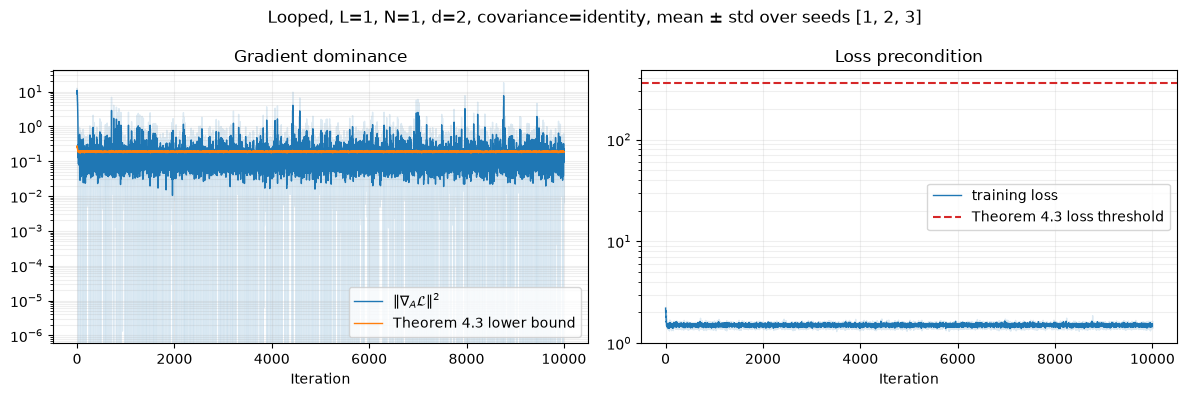

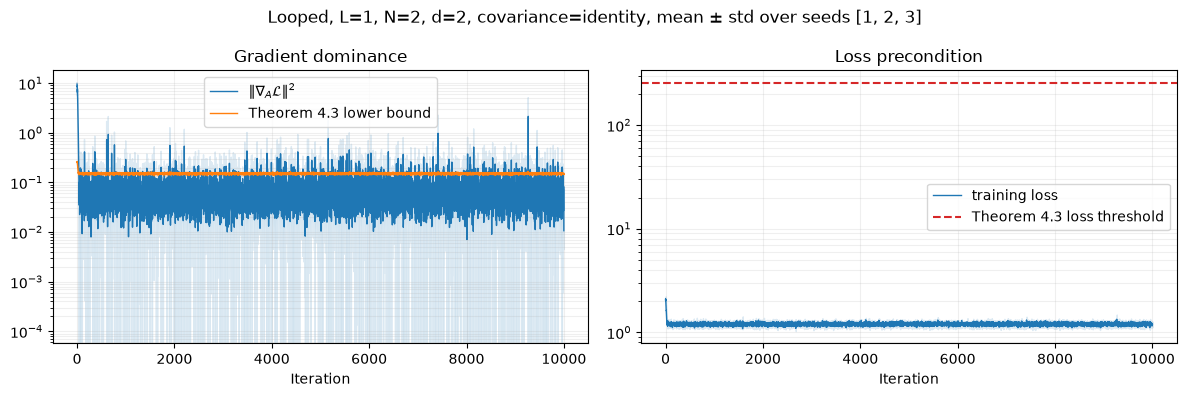

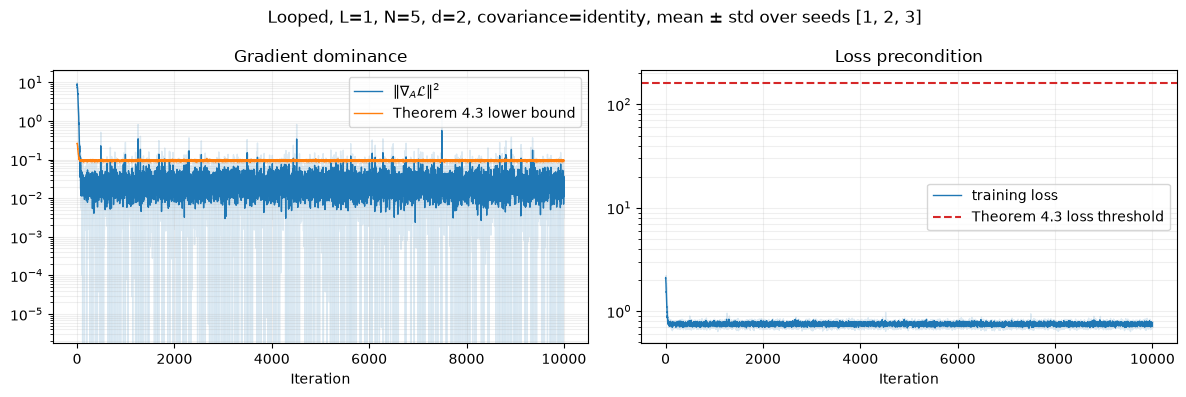

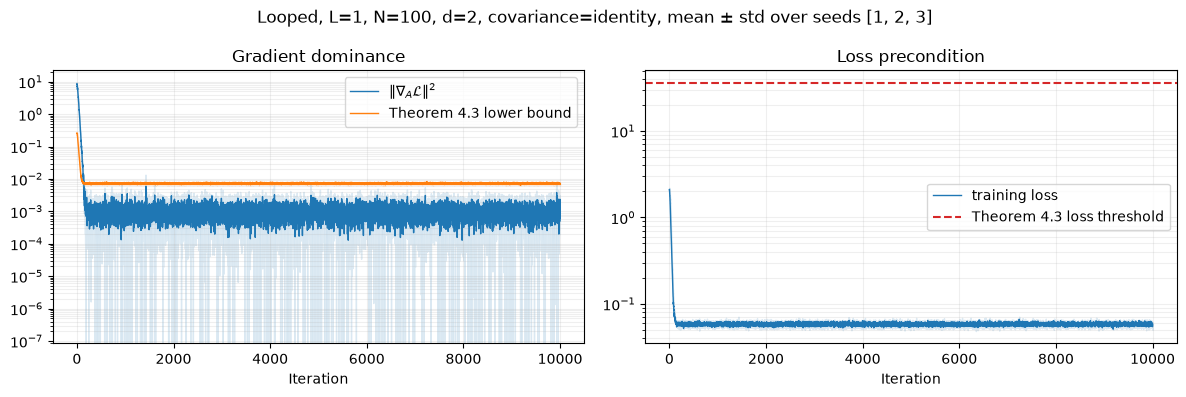

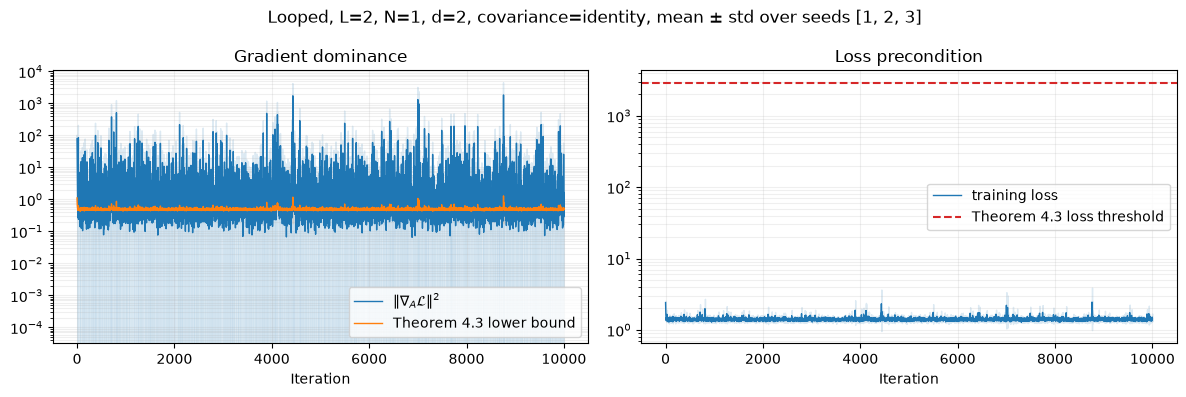

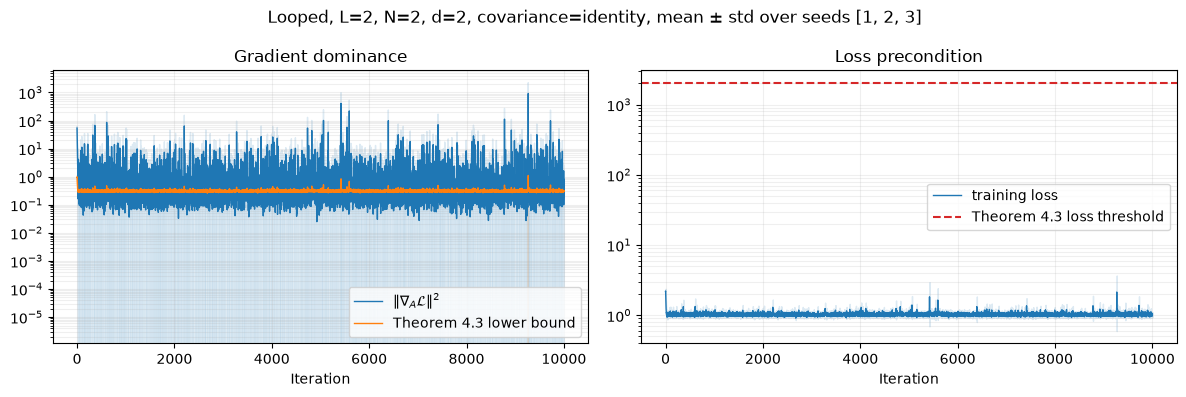

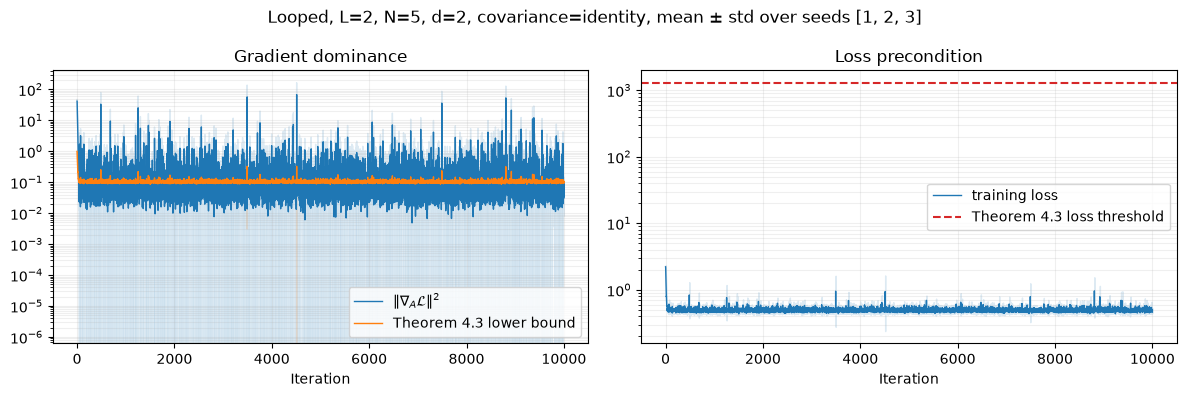

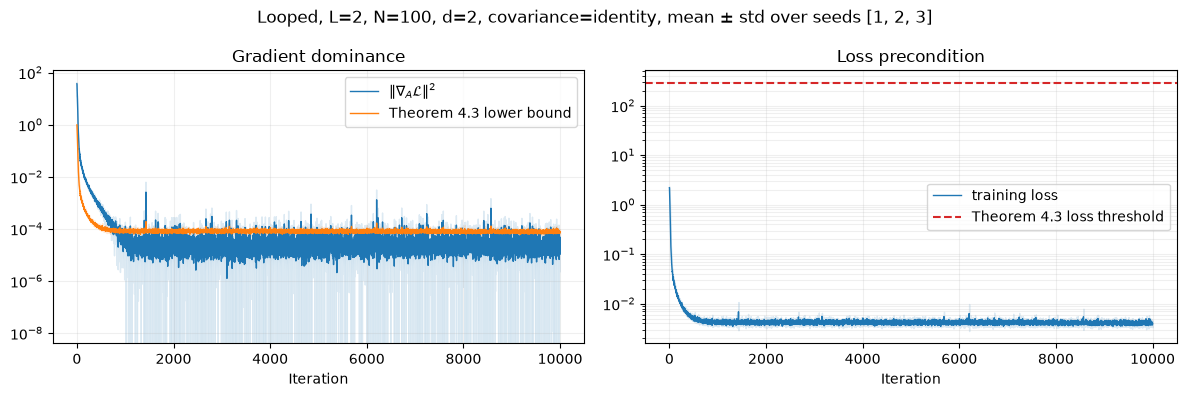

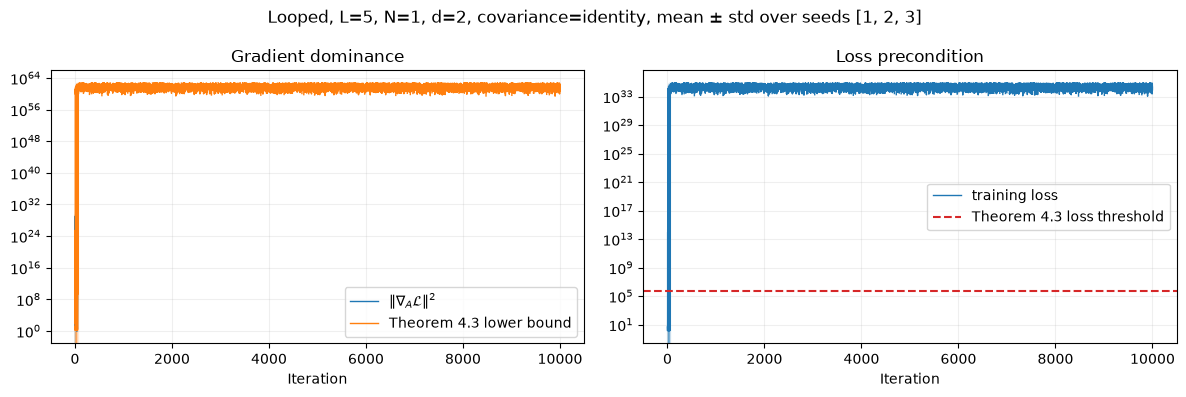

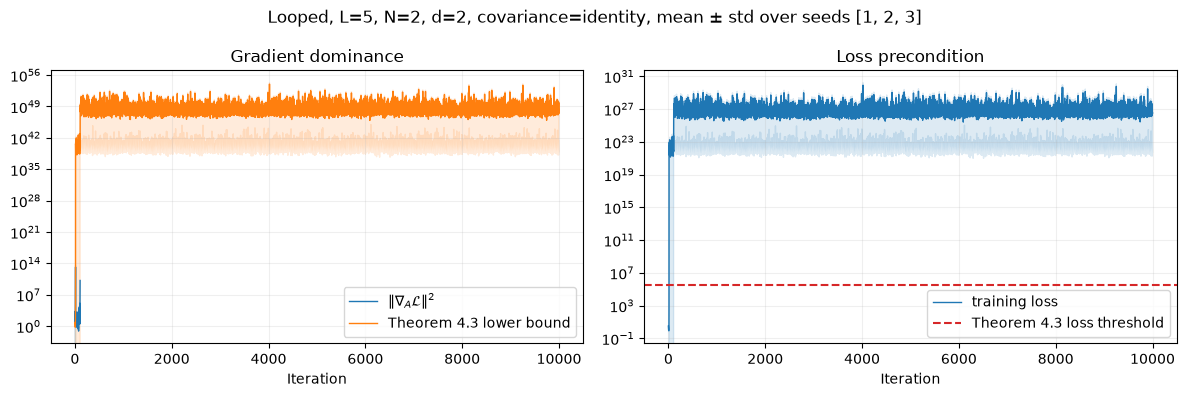

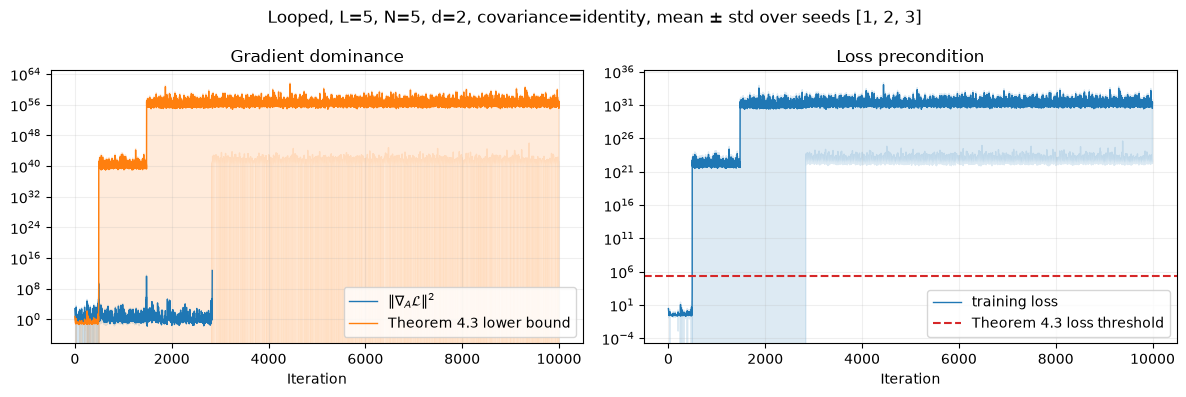

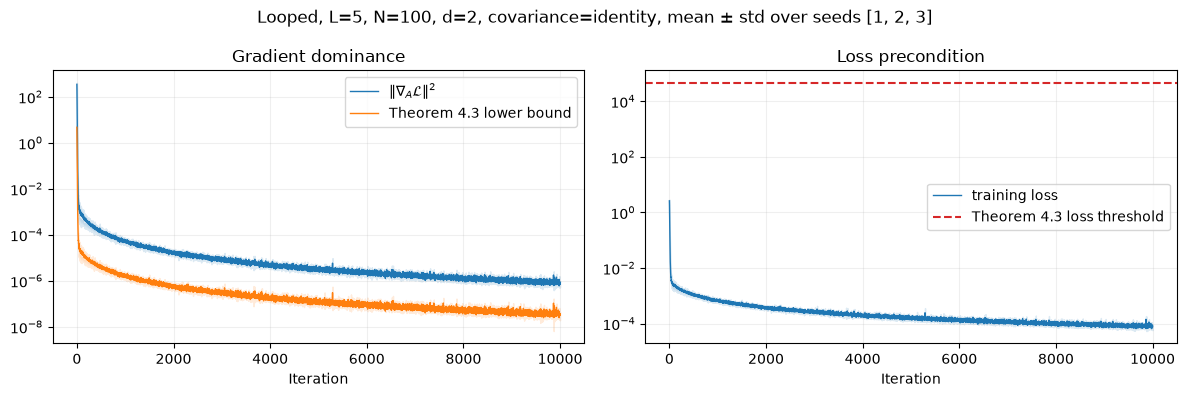

In [9]:
# ||grad_A L||^2 against the Theorem 4.3 lower bound over training.
plot_iters = 10000  # only plot the first plot_iters iterations
plot_gradient_dominance(gd_results, plot_iters=10000)

## Non-identity population covariance

Same experiment with covariates $x \sim \mathcal{N}(0, \Sigma^*)$ where $\Sigma^* = U D^2 U^\top$, using the rotation $U$ and scaling $D$ from `oos_regular_experiments.ipynb`. `generate_data` also draws $w^* \sim \mathcal{N}(0, \Sigma^{*-1})$ in this case, matching the paper's setup. Theorem 4.3 is only proven for $\Sigma^* = I$.

In [31]:
# Covariance configuration from oos_regular_experiments.ipynb (defined for d = 5).
cov_d = 5
torch.manual_seed(1234)
rotation_seed_matrix = (2 * torch.rand(cov_d, cov_d, device=device)) - 1
U_cov = torch.linalg.svd(rotation_seed_matrix, full_matrices=True).U
D_cov = torch.diag(torch.tensor([1, 1, 0.5, 0.25, 1], device=device))

cov_seeds = gd_seeds
cov_loop_counts = gd_loop_counts
cov_context_lengths = gd_context_lengths

Sigma_cov = U_cov @ D_cov @ D_cov @ U_cov.T
print('Population covariance eigenvalues:', torch.linalg.eigvalsh(Sigma_cov).cpu().numpy())
for L in cov_loop_counts:
    for n in cov_context_lengths:
        print(f'L={L}, n={n}: loss lower bound = {get_loss_lower_bound(cov_d, L, n):.2f}')

Population covariance eigenvalues: [0.06 0.25 1.   1.   1.  ]
L=1, n=2: loss lower bound = 2529.82


## Parameter matrices

Final $P$ and $Q$ for each run, plotted with `plot_parameter_matrices` from `experiments_helper.py`. $P$'s top-left block should be all zeros, since it is frozen. The model adds the attention output where the paper subtracts it, so the learned $Q$ corresponds to $-A$. For identity covariance, Theorem 4.1 predicts $A \approx \Sigma^{*-1} = I$, so $Q$ should be close to $-I$.

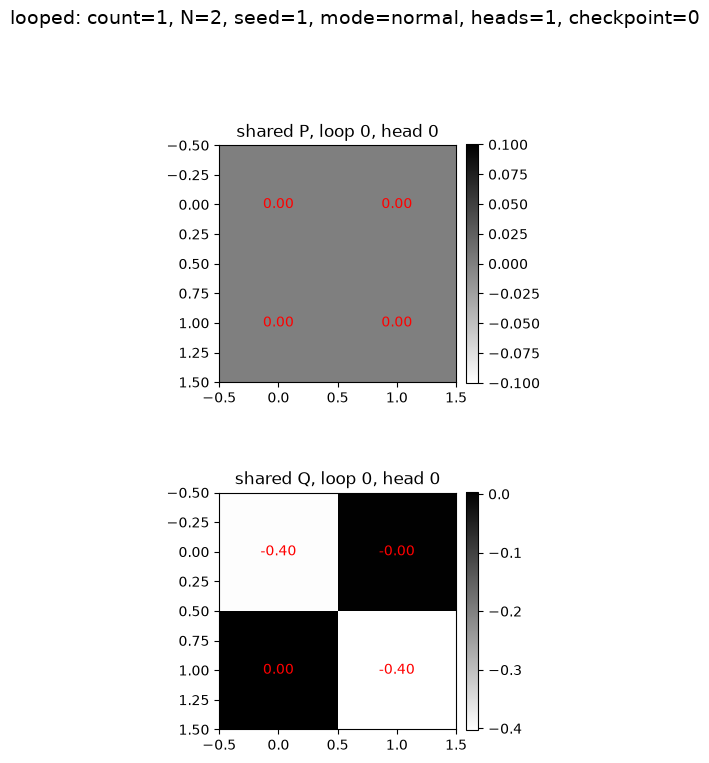

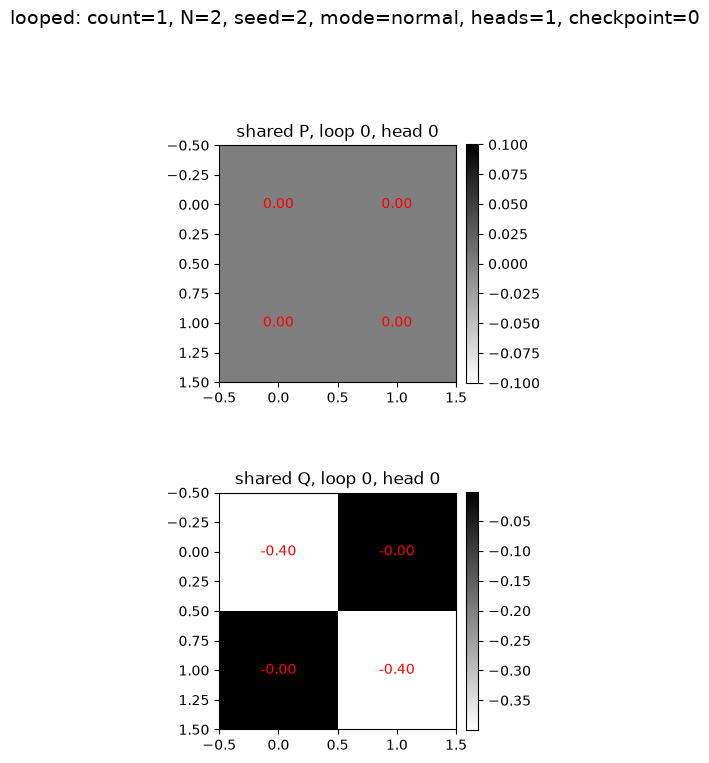

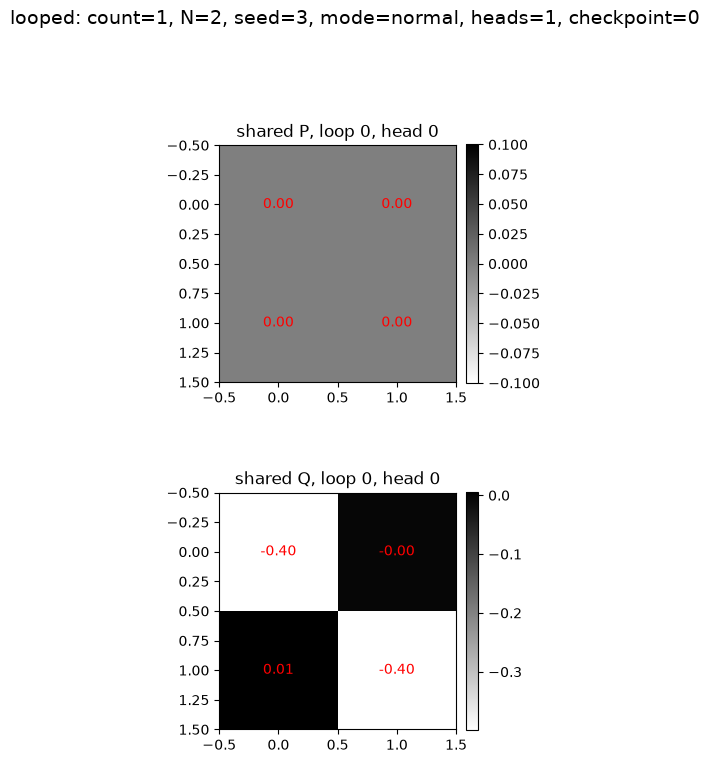

In [33]:
from experiments_helper import plot_parameter_matrices

# plot_parameter_matrices expects {(seed, count, model_type, N): [params, ...]},
# so wrap each run's final parameters as a one-checkpoint history.
gd_param_hist = {(seed, L, 'looped', N): [record['final_params']]
                 for (seed, L, N), record in gd_results.items()}
gd_param_dir = os.path.join('figures', 'gradient_dominance', 'parameters')
os.makedirs(gd_param_dir, exist_ok=True)

for seed in gd_seeds:
    plot_parameter_matrices(gd_param_hist, seed, gd_loop_counts, ['looped'], n_head,
                            fig_dir=gd_param_dir)